In [ ]:
!pip install "thefittest[torch]" 

In [1]:
!pip install matplotlib networkx



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## Iris flower data set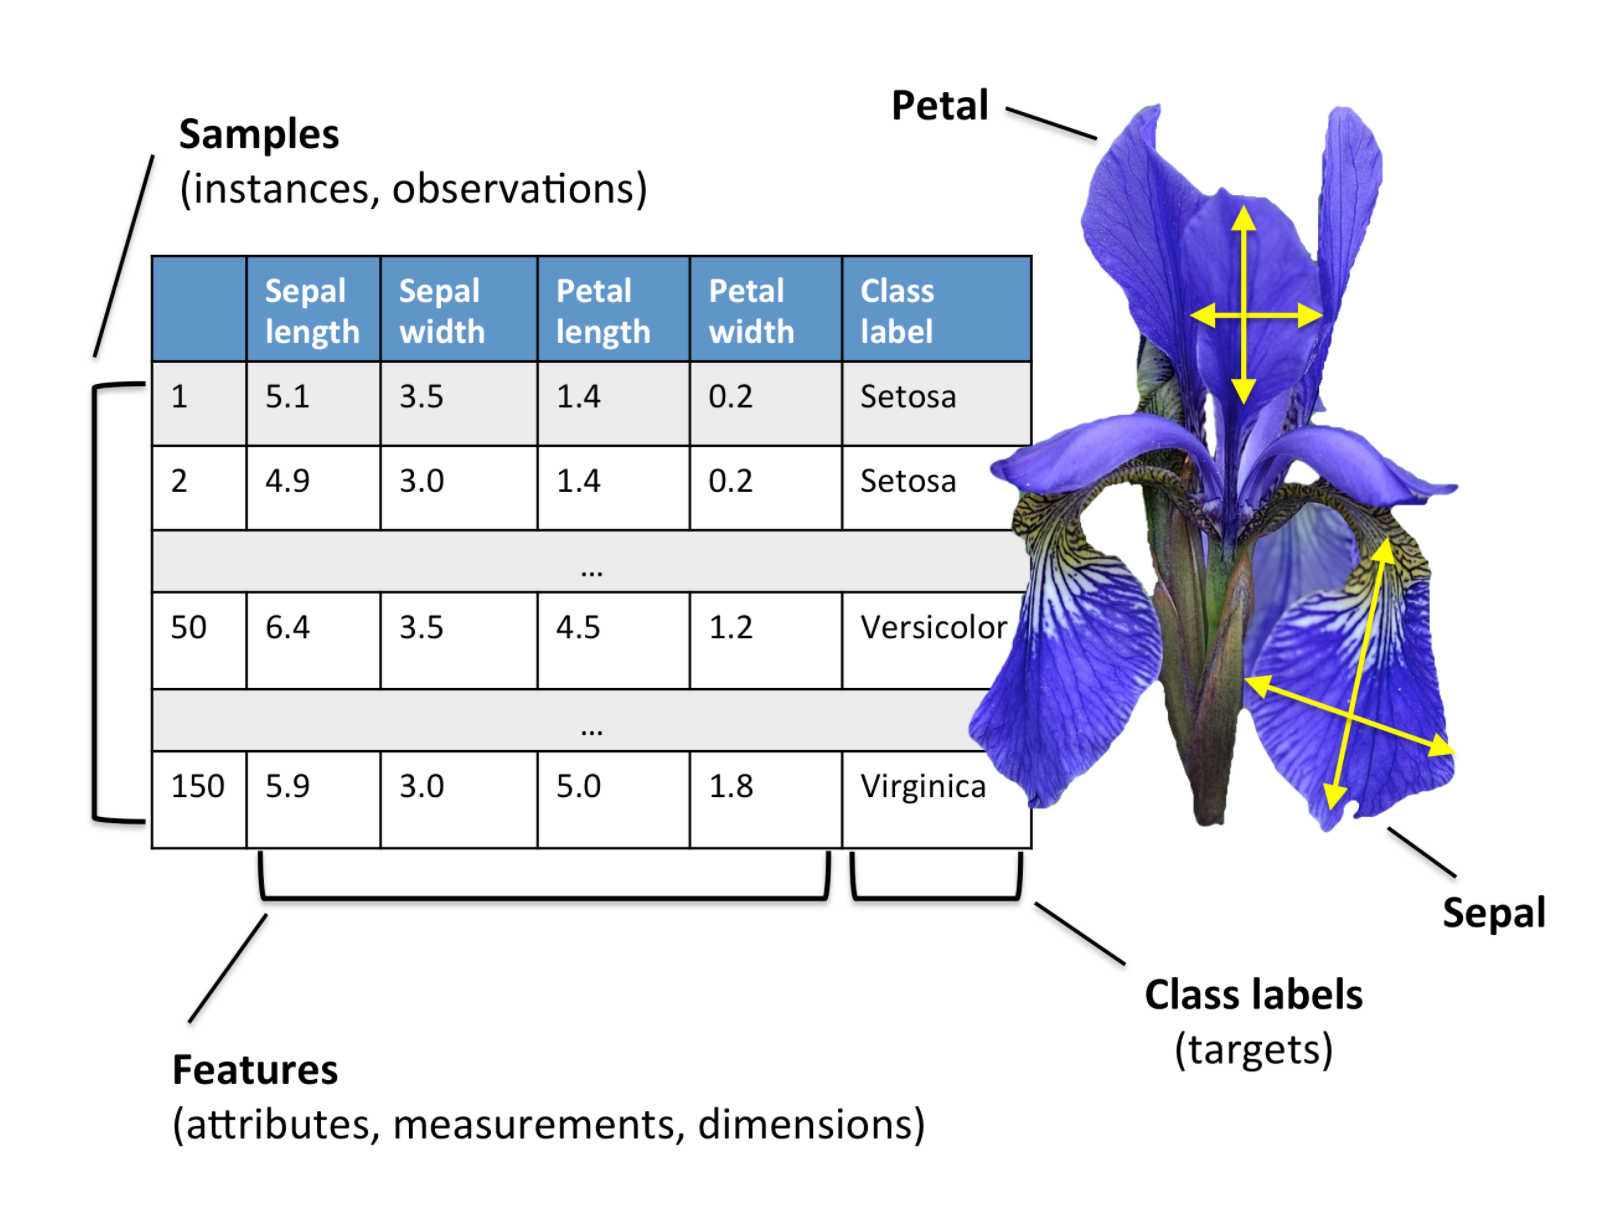

In [2]:
from thefittest.optimizers import SHAGA
from thefittest.benchmarks import IrisDataset
from thefittest.classifiers import MLPEAClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import minmax_scale
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score


data = IrisDataset()
X = data.get_X()
y = data.get_y()

X_scaled = minmax_scale(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.1)

model = MLPEAClassifier(n_iter=500,
                        pop_size=500,
                        hidden_layers = [5, 5],
                        weights_optimizer=SHAGA,
                        weights_optimizer_args={"show_progress_each": 10})

model.fit(X_train, y_train)
predict = model.predict(X_test)


print("confusion_matrix: \n", confusion_matrix(y_test, predict))
print("f1_score: \n", f1_score(y_test, predict, average="macro"))



0-th iteration with the best fitness = 1.2876867055892944
10-th iteration with the best fitness = 0.39334172010421753
20-th iteration with the best fitness = 0.39334172010421753
30-th iteration with the best fitness = 0.31924277544021606
40-th iteration with the best fitness = 0.22673997282981873
50-th iteration with the best fitness = 0.21467731893062592
60-th iteration with the best fitness = 0.17732489109039307
70-th iteration with the best fitness = 0.15340623259544373
80-th iteration with the best fitness = 0.13794855773448944
90-th iteration with the best fitness = 0.12410278618335724
100-th iteration with the best fitness = 0.11307722330093384
110-th iteration with the best fitness = 0.1048954427242279
120-th iteration with the best fitness = 0.09905454516410828
130-th iteration with the best fitness = 0.09515286237001419
140-th iteration with the best fitness = 0.0909203290939331
150-th iteration with the best fitness = 0.08436425775289536
160-th iteration with the best fitness

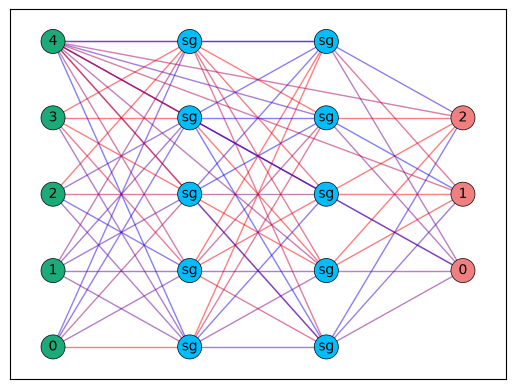

In [3]:
net = model.get_net()
net.plot()

## Regression problem

$$y = \frac{1}{2} x \sin(3 x)$$

In [4]:
import numpy as np


def problem(x):
    return np.sin(x[:,0]*3)*x[:,0]*0.5

In [13]:
import torch
import torch.optim as optim

from thefittest.regressors import MLPEARegressor
from sklearn.preprocessing import scale
from sklearn.metrics import r2_score

n_dimension = 1
left_border = -4.5
right_border = 4.5
sample_size = 100

X = np.array([np.linspace(left_border, right_border, sample_size)
              for _ in range(n_dimension)]).T
noise = np.random.normal(0, 0.1, size=sample_size)
y = problem(X) + noise

X_scaled = scale(X)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.1
)

device = "cuda" if torch.cuda.is_available() else "cpu"

model = MLPEARegressor(
    n_iter=1000,
    hidden_layers=[15, 15],
    weights_optimizer=optim.Adam,
    weights_optimizer_args={"lr": 0.01, "show_progress_each": 50},
    device=device,
)

model.fit(X_train, y_train)
predict = model.predict(X_test)

print("r2_score:", r2_score(y_test, predict))

[epoch 0/1000] loss=0.908808
[epoch 50/1000] loss=0.839307
[epoch 100/1000] loss=0.837260
[epoch 150/1000] loss=0.836001
[epoch 200/1000] loss=0.834047
[epoch 250/1000] loss=0.828004
[epoch 300/1000] loss=0.786507
[epoch 350/1000] loss=0.638980
[epoch 400/1000] loss=0.469814
[epoch 450/1000] loss=0.399824
[epoch 500/1000] loss=0.365328


/Users/user/thefittest/src/thefittest/base/_mlp.py:141: RuntimeWarning: `pop_size` игнорируется для torch.optim.* оптимизаторов.
  warnings.warn(


[epoch 550/1000] loss=0.297898
[epoch 600/1000] loss=0.191430
[epoch 650/1000] loss=0.167586
[epoch 700/1000] loss=0.158571
[epoch 750/1000] loss=0.153334
[epoch 800/1000] loss=0.150285
[epoch 850/1000] loss=0.148051
[epoch 900/1000] loss=0.145795
[epoch 950/1000] loss=0.144514
r2_score: 0.9872591264863125


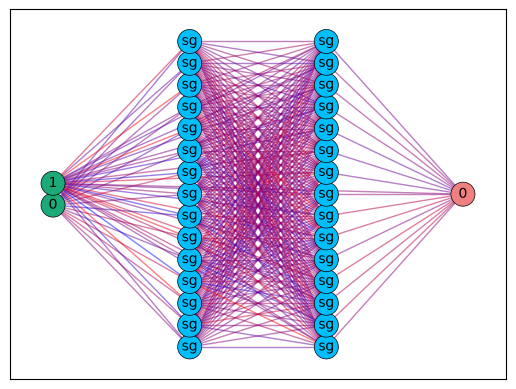

In [14]:
net = model.get_net()
net.plot()